# Materi 5 — Penyusunan Roadmap Implementasi AI di Tiap Divisi
**Pelatihan Gen AI Integrated Data Science**

---

## Tujuan pembelajaran
1. Mengukur **tingkat kematangan AI** tiap divisi secara kuantitatif (asesmen 6 dimensi, grafik radar).
2. Menyusun **inventaris use case** dan memperkaya ide dengan bantuan LLM secara terstruktur.
3. Membangun **model skor prioritas berbobot** dan menguji **sensitivitas** bobotnya.
4. Memetakan use case pada **matriks nilai vs kemudahan** (Quick Win, Strategic Bet, Fill-in, Tunda).
5. Menyusun **roadmap 3 fase** (0–3, 3–9, 9–18 bulan), menghitung **ROI & payback**, dan membuat **Gantt chart**.
6. Menghasilkan **RACI**, narasi roadmap, dan file Excel roadmap siap presentasi.

```
 Asesmen kematangan ─► Inventaris use case ─► Skor & prioritas ─► Fase & jadwal ─► ROI ─► Tata kelola ─► Dokumen roadmap
```
> Semua angka biaya, manfaat, dan skor pada notebook ini adalah **ilustrasi** untuk latihan. Ganti dengan hasil workshop divisi Anda.

## Langkah 0 — Library
| Library | Kegunaan |
|---|---|
| `pandas`, `numpy` | Tabel use case, skor, perhitungan ROI |
| `matplotlib` | Radar kematangan, matriks prioritas, Gantt chart, kurva arus kas |
| `scipy.stats.spearmanr` | Mengukur kestabilan peringkat saat bobot diubah (uji sensitivitas) |
| `openpyxl` | Menulis roadmap ke Excel |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr

MERAH, GELAP, ABU, MUDA = "#C8102E", "#1F2A37", "#8A94A6", "#E9ECF1"
WARNA_FASE = {"Fase 1 · Quick Win": MERAH, "Fase 2 · Scale-up": GELAP, "Fase 3 · Transformasi": ABU, "Backlog": "#C9CED6"}
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 60)

**Penjelasan kode**
- `Patch` — objek kotak warna untuk membuat legenda manual (dipakai di Gantt chart).
- `spearmanr` — korelasi peringkat Spearman: 1 = urutan identik, 0 = tidak berhubungan.
- `WARNA_FASE` — kamus warna per fase agar semua grafik konsisten.

## Langkah 1 — Asesmen kematangan AI per divisi
Setiap divisi menilai dirinya pada **6 dimensi** (skala 1–5) melalui workshop/kuesioner:

| Dimensi | Pertanyaan kunci |
|---|---|
| Strategi | Apakah ada target bisnis yang jelas untuk AI? |
| Data | Apakah data tersedia, bersih, dan mudah diakses? |
| Teknologi | Apakah tools & infrastruktur tersedia? |
| SDM | Apakah ada Power User / talenta data? |
| Proses | Apakah proses terdokumentasi & siap diotomasi? |
| Tata Kelola | Apakah ada kebijakan, keamanan data, dan review? |

Level kematangan: **1 Eksplorasi · 2 Eksperimen · 3 Terstandar · 4 Terintegrasi · 5 Transformatif**.

In [2]:
DIMENSI = ["Strategi", "Data", "Teknologi", "SDM", "Proses", "Tata Kelola"]
asesmen = pd.DataFrame({
    "Sales":       [3.5, 3.0, 3.0, 2.5, 3.0, 2.5],
    "Marketing":   [3.0, 2.5, 2.5, 3.0, 2.0, 2.0],
    "Produksi":    [3.0, 3.5, 3.5, 2.0, 4.0, 3.0],
    "Quality":     [3.5, 3.0, 2.5, 2.5, 3.5, 3.0],
    "SCM":         [2.5, 3.0, 3.0, 2.0, 3.0, 2.5],
    "After Sales": [3.0, 2.5, 2.0, 2.0, 3.0, 2.0],
    "Finance":     [2.5, 3.5, 3.0, 2.0, 3.5, 3.5],
    "HR":          [2.0, 2.0, 2.0, 2.0, 2.5, 2.5],
}, index=DIMENSI).T

asesmen["Rata-rata"] = asesmen[DIMENSI].mean(axis=1).round(2)
LEVEL = {1: "Eksplorasi", 2: "Eksperimen", 3: "Terstandar", 4: "Terintegrasi", 5: "Transformatif"}
asesmen["Level"] = asesmen["Rata-rata"].apply(lambda x: f"{int(x)} · {LEVEL[int(x)]}")
asesmen["Dimensi terlemah"] = asesmen[DIMENSI].idxmin(axis=1)
asesmen.sort_values("Rata-rata", ascending=False)

,Strategi,Data,Teknologi,SDM,Proses,Tata Kelola,Rata-rata,Level,Dimensi terlemah
Produksi,3.0,3.5,3.5,2.0,4.0,3.0,3.17,3 · Terstandar,SDM
Quality,3.5,3.0,2.5,2.5,3.5,3.0,3.00,3 · Terstandar,Teknologi
Finance,2.5,3.5,3.0,2.0,3.5,3.5,3.00,3 · Terstandar,SDM
Sales,3.5,3.0,3.0,2.5,3.0,2.5,2.92,2 · Eksperimen,SDM
SCM,2.5,3.0,3.0,2.0,3.0,2.5,2.67,2 · Eksperimen,SDM
Marketing,3.0,2.5,2.5,3.0,2.0,2.0,2.50,2 · Eksperimen,Proses
After Sales,3.0,2.5,2.0,2.0,3.0,2.0,2.42,2 · Eksperimen,Teknologi
HR,2.0,2.0,2.0,2.0,2.5,2.5,2.17,2 · Eksperimen,Strategi


**Penjelasan kode**
- DataFrame dibuat dengan divisi sebagai kolom lalu di-*transpose* (`.T`) agar setiap **baris = divisi** dan **kolom = dimensi**.
- `mean(axis=1)` — rata-rata **per baris** (per divisi). `axis=0` berarti per kolom.
- `.apply(lambda x: ...)` — menerapkan fungsi kecil ke setiap nilai; `int(x)` membulatkan ke bawah untuk menentukan level (2,9 → level 2). Level dipakai konservatif: divisi baru naik level jika rata-ratanya benar-benar mencapai angka bulat berikutnya.
- `idxmin(axis=1)` — nama kolom dengan nilai terendah di setiap baris → **dimensi prioritas perbaikan** tiap divisi.

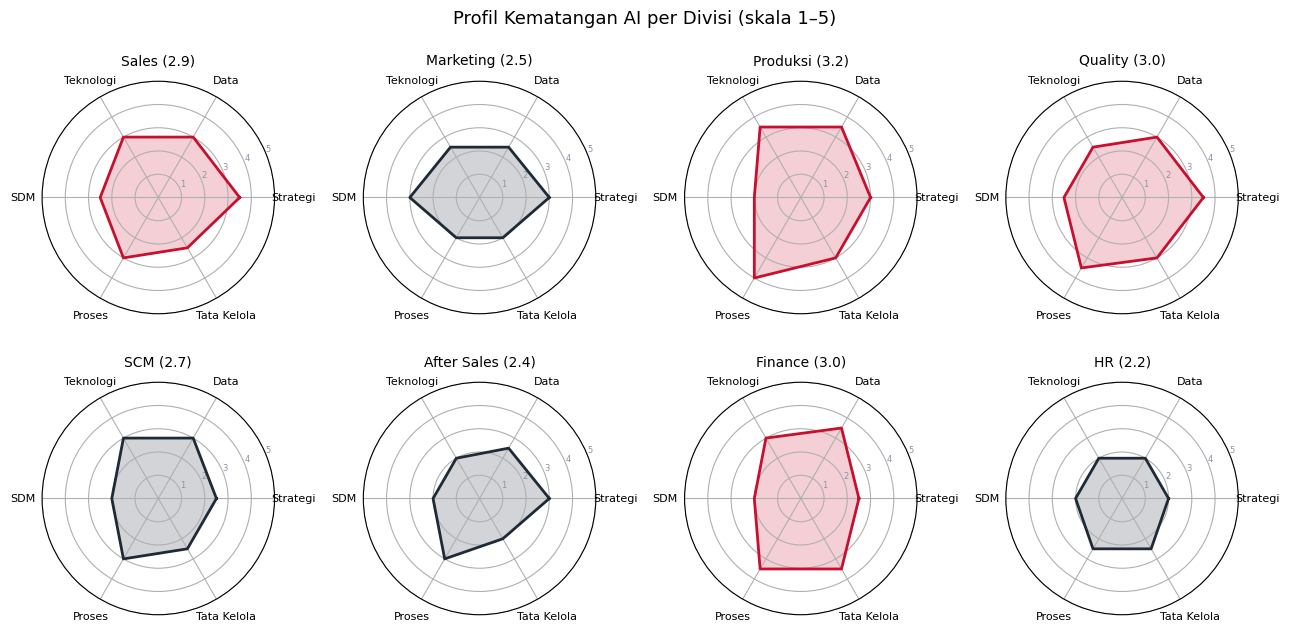

In [3]:
def radar(ax, nilai, label, warna, judul):
    sudut = np.linspace(0, 2 * np.pi, len(label), endpoint=False).tolist()
    nilai = list(nilai) + [nilai[0]]              # tutup poligon
    sudut += sudut[:1]
    ax.plot(sudut, nilai, color=warna, linewidth=2)
    ax.fill(sudut, nilai, color=warna, alpha=0.20)
    ax.set_xticks(sudut[:-1])
    ax.set_xticklabels(label, fontsize=8)
    ax.set_ylim(0, 5)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_yticklabels(["1", "2", "3", "4", "5"], fontsize=6, color=ABU)
    ax.set_title(judul, fontsize=10, pad=12)


fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), subplot_kw={"projection": "polar"})
for ax, (divisi, r) in zip(axes.ravel(), asesmen.iterrows()):
    radar(ax, r[DIMENSI].values, DIMENSI, MERAH if r["Rata-rata"] >= 2.9 else GELAP,
          f"{divisi} ({r['Rata-rata']:.1f})")
plt.suptitle("Profil Kematangan AI per Divisi (skala 1–5)", fontsize=13)
plt.tight_layout()
plt.savefig("radar_kematangan.png", dpi=150)
plt.show()

**Penjelasan kode**
- `np.linspace(0, 2π, 6, endpoint=False)` — 6 sudut yang sama rata di lingkaran, satu untuk tiap dimensi.
- `nilai + [nilai[0]]` dan `sudut + sudut[:1]` — mengulang titik pertama di akhir agar garis radar **tertutup**.
- `subplot_kw={"projection": "polar"}` — membuat semua subplot menjadi koordinat polar (lingkaran).
- `ax.fill(..., alpha=0.20)` — area transparan 20% sehingga bentuk profil mudah dibandingkan.
- `axes.ravel()` — meratakan grid 2×4 menjadi list 8 axes agar bisa di-*zip* dengan 8 divisi.
- Warna merah = divisi relatif lebih matang (kandidat pelopor), gelap = perlu penguatan fondasi.

## Langkah 2 — Inventaris use case
Hasil workshop dengan tiap divisi dikumpulkan dalam satu tabel. Setiap use case dinilai 1–5 pada:
- **nilai_bisnis** — dampak ke pendapatan, biaya, kualitas, atau kepuasan pelanggan.
- **kelayakan_teknis** — kemudahan teknis dengan tools yang ada.
- **kesiapan_data** — ketersediaan & kualitas data.
- **risiko** — risiko keamanan data, kepatuhan, reputasi (5 = paling berisiko).

Ditambah estimasi **manfaat per tahun**, **biaya implementasi** (juta Rupiah), dan **durasi** (bulan).

In [4]:
KOLOM = ["id", "divisi", "use_case", "materi_terkait", "nilai_bisnis", "kelayakan_teknis",
         "kesiapan_data", "risiko", "manfaat_juta_thn", "biaya_juta", "durasi_bln"]
use_case = pd.DataFrame([
    ("UC01", "IT/Data",     "Fondasi: platform data & tata kelola AI",           "M3", 4, 3, 3, 2, 0,    900, 6),
    ("UC02", "Sales",       "Laporan kinerja penjualan otomatis",                "M4", 4, 5, 4, 1, 420,  150, 2),
    ("UC03", "Sales",       "Prediksi permintaan per model & wilayah",           "M2", 5, 3, 4, 2, 2400, 800, 6),
    ("UC04", "Sales",       "Asisten tanya-data (Text-to-SQL) untuk manajer",    "M3", 3, 4, 4, 3, 300,  250, 3),
    ("UC05", "Marketing",   "Analisis sentimen media sosial & ulasan",           "M1", 3, 4, 3, 2, 350,  200, 3),
    ("UC06", "Marketing",   "Draf konten promosi dealer dengan Gen AI",          "M2", 3, 5, 4, 3, 280,  90,  2),
    ("UC07", "Produksi",    "Predictive maintenance mesin lini produksi",        "M2", 5, 2, 3, 2, 3000, 1500, 9),
    ("UC08", "Quality",     "Klasifikasi keluhan & klaim garansi otomatis",      "M1", 4, 4, 4, 2, 650,  220, 3),
    ("UC09", "Quality",     "Deteksi cacat visual (computer vision)",            "M1", 5, 2, 2, 2, 1800, 1400, 12),
    ("UC10", "SCM",         "Optimasi stok suku cadang dealer",                  "M2", 5, 3, 3, 2, 2100, 700, 6),
    ("UC11", "SCM",         "Peringatan dini keterlambatan pemasok",             "M4", 3, 3, 2, 2, 500,  300, 4),
    ("UC12", "After Sales", "Asisten SOP servis (RAG) untuk mekanik",            "M3", 4, 4, 4, 2, 520,  260, 3),
    ("UC13", "After Sales", "Pengingat servis cerdas & prediksi churn",          "M2", 4, 3, 3, 3, 900,  400, 5),
    ("UC14", "Finance",     "Deteksi anomali transaksi & rekonsiliasi",          "M4", 4, 3, 4, 3, 750,  350, 4),
    ("UC15", "Finance",     "Ringkasan laporan keuangan otomatis",               "M4", 3, 4, 4, 4, 200,  120, 2),
    ("UC16", "HR",          "Asisten kebijakan HR (RAG) untuk karyawan",         "M3", 3, 4, 3, 3, 250,  160, 3),
    ("UC17", "HR",          "Analisis kebutuhan pelatihan dari data kinerja",    "M2", 2, 3, 2, 4, 120,  150, 4),
], columns=KOLOM)
print(len(use_case), "use case dari", use_case["divisi"].nunique(), "divisi")
use_case

17 use case dari 9 divisi


,id,divisi,use_case,materi_terkait,nilai_bisnis,kelayakan_teknis,kesiapan_data,risiko,manfaat_juta_thn,biaya_juta,durasi_bln
0,UC01,IT/Data,Fondasi: platform data & tata kelola AI,M3,4,3,3,2,0,900,6
1,UC02,Sales,Laporan kinerja penjualan otomatis,M4,4,5,4,1,420,150,2
2,UC03,Sales,Prediksi permintaan per model & wilayah,M2,5,3,4,2,2400,800,6
3,UC04,Sales,Asisten tanya-data (Text-to-SQL) untuk manajer,M3,3,4,4,3,300,250,3
4,UC05,Marketing,Analisis sentimen media sosial & ulasan,M1,3,4,3,2,350,200,3
5,UC06,Marketing,Draf konten promosi dealer dengan Gen AI,M2,3,5,4,3,280,90,2
6,UC07,Produksi,Predictive maintenance mesin lini produksi,M2,5,2,3,2,3000,1500,9
7,UC08,Quality,Klasifikasi keluhan & klaim garansi otomatis,M1,4,4,4,2,650,220,3
8,UC09,Quality,Deteksi cacat visual (computer vision),M1,5,2,2,2,1800,1400,12
9,UC10,SCM,Optimasi stok suku cadang dealer,M2,5,3,3,2,2100,700,6


**Penjelasan kode**
- Data dimasukkan sebagai **list of tuple** + daftar nama kolom — ringkas untuk tabel kecil. Untuk tabel hasil workshop, biasanya dibaca dari Excel: `pd.read_excel("inventaris_use_case.xlsx")`.
- Kolom `materi_terkait` menghubungkan use case dengan materi pelatihan ini (M1–M4) → peserta langsung melihat keterampilan yang dibutuhkan.
- UC01 (fondasi data) sengaja bermanfaat langsung 0 — nilainya muncul karena **memungkinkan** use case lain (dependensi).

## Lapisan LLM — untuk curah gagasan use case dan narasi roadmap

In [5]:
# ============================================================
# LAPISAN LLM: satu "pintu" untuk semua pemanggilan Gen AI
# ============================================================
import os, json, re, time
import requests

# --- Konfigurasi (bisa diubah lewat environment variable) ---
LLM_MODE     = os.getenv("LLM_MODE", "simulasi")            # "simulasi" | "anthropic" | "openai_compatible"
LLM_MODEL    = os.getenv("LLM_MODEL", "claude-sonnet-5-5")  # nama model sesuai penyedia
LLM_BASE_URL = os.getenv("LLM_BASE_URL", "http://localhost:11434/v1")  # untuk openai_compatible (mis. Ollama lokal)


class LLMClient:
    """Pembungkus (wrapper) agar kode analisis tidak terikat pada satu vendor AI."""

    def __init__(self, mode=LLM_MODE, model=LLM_MODEL, simulator=None):
        self.mode = mode            # cara memanggil model
        self.model = model          # nama model
        self.simulator = simulator  # fungsi pengganti LLM untuk mode 'simulasi' (offline)
        self.log = []               # jejak audit setiap pemanggilan

    def generate(self, prompt, system="Anda adalah analis data yang teliti.",
                 temperature=0.0, max_tokens=1200):
        t0 = time.time()
        if self.mode == "anthropic":
            teks = self._panggil_anthropic(prompt, system, temperature, max_tokens)
        elif self.mode == "openai_compatible":
            teks = self._panggil_openai_compatible(prompt, system, temperature, max_tokens)
        else:
            teks = self.simulator(prompt, system)
        # catat metadata (BUKAN isi prompt) untuk audit & monitoring biaya
        self.log.append({
            "waktu": time.strftime("%Y-%m-%d %H:%M:%S"),
            "mode": self.mode,
            "panjang_prompt": len(prompt),
            "panjang_jawaban": len(teks),
            "durasi_detik": round(time.time() - t0, 3),
        })
        return teks

    def _panggil_anthropic(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers={"x-api-key": os.environ["ANTHROPIC_API_KEY"],
                     "anthropic-version": "2023-06-01",
                     "content-type": "application/json"},
            json={"model": self.model, "max_tokens": max_tokens, "temperature": temperature,
                  "system": system, "messages": [{"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()                      # hentikan jika HTTP error (401, 429, dst.)
        return r.json()["content"][0]["text"]     # ambil teks jawaban pertama

    def _panggil_openai_compatible(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            f"{LLM_BASE_URL}/chat/completions",
            headers={"Authorization": f"Bearer {os.getenv('LLM_API_KEY', 'tidak-perlu')}"},
            json={"model": self.model, "temperature": temperature, "max_tokens": max_tokens,
                  "messages": [{"role": "system", "content": system},
                               {"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()
        return r.json()["choices"][0]["message"]["content"]


def ambil_json(teks):
    """Mengambil objek/array JSON dari jawaban LLM yang kadang dibungkus ```json ...```
    atau diawali kalimat pembuka."""
    teks = re.sub(r"```(?:json)?", "", teks)
    kandidat = [i for i in (teks.find("{"), teks.find("[")) if i != -1]
    if not kandidat:
        raise ValueError("Tidak ditemukan JSON pada jawaban LLM")
    awal = min(kandidat)
    akhir = teks.rfind("}" if teks[awal] == "{" else "]")
    return json.loads(teks[awal:akhir + 1])

print("Mode LLM aktif:", LLM_MODE)

Mode LLM aktif: simulasi


### Penjelasan kode — Lapisan LLM

Sel ini adalah **fondasi** semua pemanggilan Gen AI di notebook. Semua langkah analisis hanya memanggil `llm.generate(prompt)`, sehingga kita bisa berganti vendor/model tanpa mengubah logika analisis.

| Bagian | Fungsi | Mengapa penting |
|---|---|---|
| `LLM_MODE = os.getenv(...)` | Membaca mode dari *environment variable*; bawaan `"simulasi"`. | Notebook tetap berjalan di kelas tanpa internet/API key. |
| `LLM_MODEL`, `LLM_BASE_URL` | Nama model & alamat server (untuk model lokal seperti Ollama). | Data sensitif bisa diproses model **lokal** di jaringan internal. |
| `class LLMClient` | *Wrapper* yang menyatukan 3 cara pemanggilan. | Prinsip *separation of concerns*: analisis ≠ koneksi API. |
| `generate()` | Memilih jalur (`anthropic` / `openai_compatible` / simulator), lalu mencatat log. | Satu titik kontrol untuk audit, biaya, dan *error handling*. |
| `self.log.append({...})` | Menyimpan waktu, mode, panjang prompt/jawaban, durasi. | Isi prompt **tidak** disimpan → mengurangi risiko kebocoran data. |
| `requests.post(...)` | Memanggil REST API. `headers` berisi kunci API; `json` berisi model, `system`, dan `messages`. | Tanpa SDK tambahan — cukup library `requests`. |
| `temperature=0.0` | Mengatur keacakan jawaban; 0 = paling konsisten. | Untuk analisis data kita butuh hasil yang **dapat diulang**. |
| `r.raise_for_status()` | Memunculkan error bila status HTTP bukan 2xx. | Error terlihat jelas, tidak diam-diam menghasilkan data kosong. |
| `ambil_json()` | Membersihkan pagar ```` ```json ```` lalu memotong dari `{`/`[` pertama sampai penutup terakhir, kemudian `json.loads`. | LLM kadang menambahkan kalimat pembuka; fungsi ini membuat parsing **tangguh**. |

**Cara memakai model sungguhan** (opsional, sebelum menjalankan notebook):
```bash
# Claude (Anthropic)
export LLM_MODE=anthropic
export ANTHROPIC_API_KEY=sk-ant-...
# atau server kompatibel OpenAI (mis. Ollama lokal / gateway internal perusahaan)
export LLM_MODE=openai_compatible
export LLM_BASE_URL=http://localhost:11434/v1
export LLM_MODEL=llama3.1
```
> ⚠️ **Kebijakan data:** jangan mengirim data rahasia/pribadi ke layanan AI publik tanpa persetujuan sesuai kebijakan perusahaan. Mode **simulasi** memakai fungsi aturan sederhana (*rule-based*) yang meniru format jawaban LLM, sehingga seluruh alur bisa dipelajari secara offline.

In [6]:
def _antara(teks, awal, akhir):
    return teks.rsplit(awal, 1)[1].split(akhir, 1)[0].strip()


IDE_SIM = {
    "After Sales": [
        {"use_case": "Ringkasan otomatis riwayat servis untuk service advisor", "nilai_bisnis": 3, "kelayakan_teknis": 4,
         "kesiapan_data": 4, "risiko": 2, "alasan": "mempercepat konsultasi & mengurangi waktu tunggu"},
        {"use_case": "Asisten SOP servis (RAG) untuk mekanik", "nilai_bisnis": 4, "kelayakan_teknis": 4,
         "kesiapan_data": 4, "risiko": 2, "alasan": "duplikat — sudah ada di inventaris"},
        {"use_case": "Klasifikasi foto kerusakan untuk estimasi biaya", "nilai_bisnis": 4, "kelayakan_teknis": 2,
         "kesiapan_data": 2, "risiko": 3, "alasan": "estimasi lebih cepat, butuh data foto berlabel"},
    ]
}


def simulator_nb05(prompt, system=None):
    if "TUGAS: IDE_USE_CASE" in prompt:
        divisi = _antara(prompt, "DIVISI:", "AKHIR_DIVISI")
        return "```json\n" + json.dumps(IDE_SIM.get(divisi, []), ensure_ascii=False, indent=1) + "\n```"
    if "TUGAS: NARASI_ROADMAP" in prompt:
        f = ambil_json(_antara(prompt, "FAKTA:", "AKHIR_FAKTA"))
        fase = f["ringkasan_fase"]
        rp = lambda x: f"{x:,}".replace(",", ".")          # 7500 → 7.500
        teks = (f"Roadmap AI {f['horizon']} memuat {f['jumlah_use_case']} use case dengan total investasi "
                f"Rp{rp(f['total_biaya_juta'])} juta dan estimasi manfaat Rp{rp(f['total_manfaat_juta_thn'])} juta per tahun "
                f"(payback portofolio ±{f['payback_bulan_portofolio']} bulan).\n\n")
        for nama, d in fase.items():
            teks += (f"• {nama}: {d['jumlah']} use case, biaya Rp{rp(d['biaya_juta'])} juta — "
                     f"contoh: {'; '.join(d['contoh'][:2])}.\n")
        teks += (f"\nPrioritas penguatan fondasi: dimensi {f['dimensi_terlemah_umum']} menjadi titik terlemah di sebagian besar divisi. "
                 "Keberhasilan Fase 1 menjadi syarat pendanaan Fase 2.")
        return teks
    return "Tugas tidak dikenali."


llm = LLMClient(simulator=simulator_nb05)

**Penjelasan kode**
- `IDE_SIM` — jawaban simulasi untuk curah gagasan divisi After Sales. Perhatikan ada satu ide yang **duplikat** dengan inventaris — kasus nyata yang sering terjadi saat memakai LLM, dan harus ditangani kode.
- Narasi roadmap disusun dari objek fakta; fungsi kecil `rp()` mengubah pemisah ribuan ke format Indonesia (7.500) tanpa mengganggu tanda koma lain di kalimat.

### Curah gagasan use case dengan LLM (terstruktur & tervalidasi)
LLM diberi **profil divisi** (skor kematangan & dimensi terlemah) dan **daftar use case yang sudah ada**, lalu diminta mengusulkan ide dalam format JSON. Ide divalidasi (rentang skor, duplikat) sebelum masuk inventaris — **usulan AI tetap perlu disetujui pemilik proses**.

In [7]:
def ide_use_case(divisi, maks=3):
    profil = asesmen.loc[divisi, DIMENSI].to_dict()
    sudah_ada = use_case.loc[use_case["divisi"] == divisi, "use_case"].tolist()
    prompt = f"""TUGAS: IDE_USE_CASE
PERAN: Konsultan AI transformation untuk industri otomotif roda dua.
KONTEKS: profil kematangan AI divisi (1-5): {profil}. Use case yang sudah ada: {sudah_ada}.
TUGAS UTAMA: Usulkan maksimal {maks} use case Gen AI/data science BARU yang realistis dalam 18 bulan.
FORMAT: JSON array; tiap item berisi use_case, nilai_bisnis, kelayakan_teknis, kesiapan_data, risiko (1-5), alasan.
BATASAN: jangan mengulang use case yang sudah ada; sesuaikan dengan dimensi terlemah divisi.
DIVISI: {divisi} AKHIR_DIVISI"""
    usulan = ambil_json(llm.generate(prompt))

    diterima, ditolak = [], []
    for u in usulan:
        skor_ok = all(1 <= int(u.get(k, 0)) <= 5 for k in ["nilai_bisnis", "kelayakan_teknis", "kesiapan_data", "risiko"])
        duplikat = u["use_case"].strip().lower() in {s.lower() for s in sudah_ada}
        (diterima if skor_ok and not duplikat else ditolak).append(
            {**u, "status": "diterima" if skor_ok and not duplikat else ("duplikat" if duplikat else "skor tidak valid")})
    return pd.DataFrame(diterima + ditolak)


usulan = ide_use_case("After Sales")
usulan

,use_case,nilai_bisnis,kelayakan_teknis,kesiapan_data,risiko,alasan,status
0,Ringkasan otomatis riwayat servis untuk service advisor,3,4,4,2,mempercepat konsultasi & mengurangi waktu tunggu,diterima
1,Klasifikasi foto kerusakan untuk estimasi biaya,4,2,2,3,"estimasi lebih cepat, butuh data foto berlabel",diterima
2,Asisten SOP servis (RAG) untuk mekanik,4,4,4,2,duplikat — sudah ada di inventaris,duplikat


**Penjelasan kode**
- `asesmen.loc[divisi, DIMENSI].to_dict()` — profil 6 dimensi divisi sebagai dict → konteks bagi LLM agar usulannya **sesuai kematangan** divisi.
- `sudah_ada` — daftar use case eksisting dimasukkan ke prompt dan juga dipakai untuk memeriksa duplikat.
- `all(1 <= int(u.get(k, 0)) <= 5 for k in [...])` — memastikan keempat skor berada di rentang 1–5.
- `(diterima if kondisi else ditolak).append(...)` — memilih list tujuan secara ringkas dengan ekspresi kondisional.
- Hasil: ide duplikat otomatis ditandai; ide yang diterima masih berstatus **usulan** untuk dibahas di workshop.

## Langkah 3 — Model skor prioritas berbobot
$$ \text{Skor} = 0{,}35\cdot\text{Nilai} + 0{,}25\cdot\text{Kelayakan} + 0{,}25\cdot\text{Kesiapan Data} + 0{,}15\cdot(6-\text{Risiko}) $$
Risiko dibalik (`6 − risiko`) agar semua komponen searah: makin tinggi makin baik.

In [8]:
BOBOT = {"nilai_bisnis": 0.35, "kelayakan_teknis": 0.25, "kesiapan_data": 0.25, "risiko_terbalik": 0.15}
assert abs(sum(BOBOT.values()) - 1) < 1e-9, "Total bobot harus 1"


def hitung_skor(df, bobot):
    d = df.copy()
    d["risiko_terbalik"] = 6 - d["risiko"]
    d["skor"] = sum(d[k] * w for k, w in bobot.items()).round(2)
    d["kemudahan"] = ((d["kelayakan_teknis"] + d["kesiapan_data"]) / 2).round(2)
    d["roi_persen"] = np.where(d["biaya_juta"] > 0,
                               ((d["manfaat_juta_thn"] - d["biaya_juta"]) / d["biaya_juta"] * 100).round(0), np.nan)
    d["payback_bln"] = np.where(d["manfaat_juta_thn"] > 0,
                                (d["biaya_juta"] / (d["manfaat_juta_thn"] / 12)).round(1), np.nan)
    return d.sort_values("skor", ascending=False).reset_index(drop=True)


uc = hitung_skor(use_case, BOBOT)
uc["peringkat"] = np.arange(1, len(uc) + 1)
uc[["peringkat", "id", "divisi", "use_case", "skor", "kemudahan", "roi_persen", "payback_bln"]]

,peringkat,id,divisi,use_case,skor,kemudahan,roi_persen,payback_bln
0,1,UC02,Sales,Laporan kinerja penjualan otomatis,4.40,4.5,180.0,4.3
1,2,UC03,Sales,Prediksi permintaan per model & wilayah,4.10,3.5,200.0,4.0
2,3,UC08,Quality,Klasifikasi keluhan & klaim garansi otomatis,4.00,4.0,195.0,4.1
3,4,UC12,After Sales,Asisten SOP servis (RAG) untuk mekanik,4.00,4.0,100.0,6.0
4,5,UC10,SCM,Optimasi stok suku cadang dealer,3.85,3.0,200.0,4.0
5,6,UC06,Marketing,Draf konten promosi dealer dengan Gen AI,3.75,4.5,211.0,3.9
6,7,UC07,Produksi,Predictive maintenance mesin lini produksi,3.60,2.5,100.0,6.0
7,8,UC14,Finance,Deteksi anomali transaksi & rekonsiliasi,3.60,3.5,114.0,5.6
8,9,UC01,IT/Data,Fondasi: platform data & tata kelola AI,3.50,3.0,-100.0,NaN
9,10,UC04,Sales,Asisten tanya-data (Text-to-SQL) untuk manajer,3.50,4.0,20.0,10.0


**Penjelasan kode**
- `assert ... < 1e-9` — pengaman: program berhenti jika total bobot tidak 1 (misalnya salah ketik 0,53). Pembandingan memakai toleransi karena bilangan desimal di komputer tidak selalu persis.
- `sum(d[k] * w for k, w in bobot.items())` — menjumlah kolom × bobot untuk semua kriteria dalam satu baris kode; menambah kriteria cukup menambah entri di `BOBOT`.
- `kemudahan` — rata-rata kelayakan teknis & kesiapan data (sumbu-X matriks prioritas).
- `roi_persen = (manfaat − biaya) / biaya × 100` — ROI tahun pertama sederhana.
- `payback_bln = biaya ÷ (manfaat per bulan)` — berapa bulan hingga investasi kembali.
- `np.where(kondisi, rumus, np.nan)` — menghindari pembagian dengan nol. UC01 (fondasi) tidak punya manfaat langsung sehingga ROI-nya −100% dan payback `NaN`; nilainya dinilai dari use case lain yang bergantung padanya, bukan dari ROI sendiri.

### Uji sensitivitas bobot
Bobot adalah hasil kesepakatan, bukan kebenaran mutlak. Kita uji: jika bobot digeser, apakah **urutan prioritas** berubah drastis? Korelasi peringkat **Spearman** mendekati 1 berarti prioritas **stabil**.

In [9]:
skenario = {
    "Dasar": BOBOT,
    "Fokus nilai":  {"nilai_bisnis": 0.50, "kelayakan_teknis": 0.20, "kesiapan_data": 0.20, "risiko_terbalik": 0.10},
    "Fokus cepat":  {"nilai_bisnis": 0.25, "kelayakan_teknis": 0.35, "kesiapan_data": 0.30, "risiko_terbalik": 0.10},
    "Hati-hati":    {"nilai_bisnis": 0.30, "kelayakan_teknis": 0.20, "kesiapan_data": 0.20, "risiko_terbalik": 0.30},
}
peringkat = pd.DataFrame({nama: hitung_skor(use_case, b).set_index("id")["skor"].rank(ascending=False)
                          for nama, b in skenario.items()})
stabilitas = {nama: round(float(spearmanr(peringkat["Dasar"], peringkat[nama])[0]), 3) for nama in skenario}
print("Korelasi Spearman vs skenario dasar:", stabilitas)

top5 = {nama: peringkat[nama].nsmallest(5).index.tolist() for nama in skenario}
pd.DataFrame(top5, index=[f"#{i}" for i in range(1, 6)])

Korelasi Spearman vs skenario dasar: {'Dasar': 1.0, 'Fokus nilai': 0.916, 'Fokus cepat': 0.86, 'Hati-hati': 0.952}


,Dasar,Fokus nilai,Fokus cepat,Hati-hati
#1,UC02,UC02,UC02,UC02
#2,UC03,UC03,UC06,UC03
#3,UC08,UC10,UC08,UC08
#4,UC12,UC08,UC12,UC12
#5,UC10,UC12,UC03,UC10


**Penjelasan kode**
- `skenario` — empat set bobot yang mewakili sudut pandang berbeda (manajemen yang mengejar nilai, tim yang ingin cepat, tim risiko).
- `.rank(ascending=False)` — skor tertinggi mendapat peringkat 1.
- *Dict comprehension* di dalam `pd.DataFrame({...})` — setiap skenario menjadi satu kolom peringkat.
- `spearmanr(a, b)[0]` — koefisien korelasi peringkat. Nilai > 0,8 → prioritas relatif tidak bergantung pada perdebatan bobot.
- `nsmallest(5)` — 5 peringkat terbaik tiap skenario. Use case yang **selalu** masuk 5 besar di semua skenario adalah kandidat paling aman untuk didanai.

## Langkah 4 — Matriks prioritas: Nilai vs Kemudahan
| Kuadran | Kriteria | Tindakan |
|---|---|---|
| **Quick Win** | nilai ≥ 3,5 & kemudahan ≥ 3,5 | Kerjakan segera (Fase 1) |
| **Strategic Bet** | nilai ≥ 3,5 & kemudahan < 3,5 | Siapkan data/teknologi, kerjakan bertahap |
| **Fill-in** | nilai < 3,5 & kemudahan ≥ 3,5 | Kerjakan saat ada kapasitas |
| **Tunda** | nilai < 3,5 & kemudahan < 3,5 | Masukkan backlog |

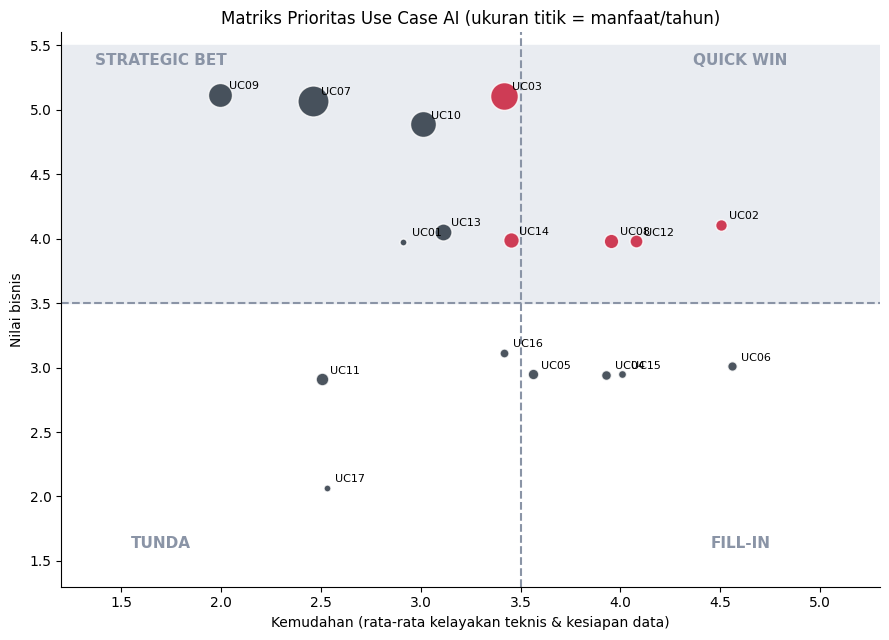

kuadran
Fill-in          [UC06, UC04, UC05, UC15, UC16]
Quick Win        [UC02, UC03, UC08, UC12, UC14]
Strategic Bet    [UC10, UC07, UC01, UC09, UC13]
Tunda                              [UC11, UC17]
Name: id, dtype: object

In [10]:
def kuadran(r, batas=3.5):
    if r["nilai_bisnis"] >= batas:
        return "Quick Win" if r["kemudahan"] >= batas else "Strategic Bet"
    return "Fill-in" if r["kemudahan"] >= batas else "Tunda"


uc["kuadran"] = uc.apply(kuadran, axis=1)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.axhspan(3.5, 5.5, xmin=0, xmax=1, color=MUDA, zorder=0)
ax.axvline(3.5, color=ABU, linestyle="--"); ax.axhline(3.5, color=ABU, linestyle="--")
geser = np.random.default_rng(1).uniform(-0.12, 0.12, size=(len(uc), 2))   # jitter agar titik tidak menumpuk
for (_, r), (dx, dy) in zip(uc.iterrows(), geser):
    x, y = r["kemudahan"] + dx, r["nilai_bisnis"] + dy
    ax.scatter(x, y, s=max(r["manfaat_juta_thn"], 150) / 6, color=MERAH if r["kuadran"] == "Quick Win" else GELAP,
               alpha=0.8, edgecolor="white")
    ax.annotate(r["id"], (x, y), fontsize=8, xytext=(6, 4), textcoords="offset points")
for teks, (x, y) in {"QUICK WIN": (4.6, 5.35), "STRATEGIC BET": (1.7, 5.35),
                     "FILL-IN": (4.6, 1.6), "TUNDA": (1.7, 1.6)}.items():
    ax.text(x, y, teks, fontsize=11, fontweight="bold", color=ABU, ha="center")
ax.set_xlim(1.2, 5.3); ax.set_ylim(1.3, 5.6)
ax.set_xlabel("Kemudahan (rata-rata kelayakan teknis & kesiapan data)")
ax.set_ylabel("Nilai bisnis")
ax.set_title("Matriks Prioritas Use Case AI (ukuran titik = manfaat/tahun)")
plt.tight_layout()
plt.savefig("matriks_prioritas.png", dpi=150)
plt.show()
uc.groupby("kuadran")["id"].apply(list)

**Penjelasan kode**
- `uc.apply(kuadran, axis=1)` — menjalankan fungsi `kuadran` untuk **setiap baris** (`axis=1`); fungsi menerima satu baris sebagai Series.
- `axhspan(3.5, 5.5)` — mewarnai latar area nilai tinggi agar mata langsung tertuju ke sana.
- *Jitter* (`geser`) — pergeseran acak kecil agar use case dengan skor sama tidak saling menutupi.
- `s=manfaat/6` — ukuran titik proporsional terhadap manfaat per tahun (dimensi ke-3 pada grafik 2D).
- `ax.annotate(id, xytext=(6, 4), textcoords="offset points")` — label ID digeser 6×4 poin dari titik.
- `groupby("kuadran")["id"].apply(list)` — daftar ID per kuadran.

## Langkah 5 — Penetapan fase & jadwal (dengan dependensi)
Aturan penetapan fase:
- **Fase 1 · Quick Win (bulan 0–3):** kuadran Quick Win dan durasi ≤ 3 bulan, **ditambah fondasi data (UC01)** yang wajib dimulai sejak awal.
- **Fase 2 · Scale-up (bulan 3–9):** Quick Win berdurasi > 3 bulan, Fill-in berisiko ≤ 3, dan Strategic Bet dengan kesiapan data ≥ 3 serta durasi < 9 bulan.
- **Fase 3 · Transformasi (bulan 9–18):** Strategic Bet yang kesiapan datanya masih < 3 (menunggu fondasi data) atau berdurasi panjang (≥ 9 bulan), serta Fill-in berisiko tinggi (perlu kajian risiko dulu).
- **Backlog:** kuadran Tunda.

In [11]:
def tetapkan_fase(r):
    if r["id"] == "UC01":
        return "Fase 1 · Quick Win"
    if r["kuadran"] == "Quick Win":
        return "Fase 1 · Quick Win" if r["durasi_bln"] <= 3 else "Fase 2 · Scale-up"
    if r["kuadran"] == "Fill-in":
        return "Fase 2 · Scale-up" if r["risiko"] <= 3 else "Fase 3 · Transformasi"
    if r["kuadran"] == "Strategic Bet":
        siap = r["kesiapan_data"] >= 3 and r["durasi_bln"] < 9
        return "Fase 2 · Scale-up" if siap else "Fase 3 · Transformasi"
    return "Backlog"


MULAI_FASE = {"Fase 1 · Quick Win": 0, "Fase 2 · Scale-up": 3, "Fase 3 · Transformasi": 9}
uc["fase"] = uc.apply(tetapkan_fase, axis=1)
uc["urut_jadwal"] = np.where(uc["id"] == "UC01", 0, uc["peringkat"])   # fondasi selalu dijadwalkan pertama

jadwal = []
kapasitas = {f: 0 for f in MULAI_FASE}                 # jumlah proyek yang sudah dijadwalkan di tiap fase
for _, r in uc[uc["fase"] != "Backlog"].sort_values(["fase", "urut_jadwal"]).iterrows():
    mulai = MULAI_FASE[r["fase"]] + (kapasitas[r["fase"]] // 3)   # maks 3 proyek mulai bersamaan per fase
    kapasitas[r["fase"]] += 1
    jadwal.append({"id": r["id"], "mulai_bln": mulai, "selesai_bln": min(mulai + r["durasi_bln"], 18)})
uc = uc.merge(pd.DataFrame(jadwal), on="id", how="left")
uc[["peringkat", "id", "divisi", "use_case", "kuadran", "fase", "mulai_bln", "selesai_bln"]].sort_values(["fase", "mulai_bln"])

,peringkat,id,divisi,use_case,kuadran,fase,mulai_bln,selesai_bln
15,16,UC11,SCM,Peringatan dini keterlambatan pemasok,Tunda,Backlog,NaN,NaN
16,17,UC17,HR,Analisis kebutuhan pelatihan dari data kinerja,Tunda,Backlog,NaN,NaN
0,1,UC02,Sales,Laporan kinerja penjualan otomatis,Quick Win,Fase 1 · Quick Win,0.0,2.0
2,3,UC08,Quality,Klasifikasi keluhan & klaim garansi otomatis,Quick Win,Fase 1 · Quick Win,0.0,3.0
8,9,UC01,IT/Data,Fondasi: platform data & tata kelola AI,Strategic Bet,Fase 1 · Quick Win,0.0,6.0
3,4,UC12,After Sales,Asisten SOP servis (RAG) untuk mekanik,Quick Win,Fase 1 · Quick Win,1.0,4.0
1,2,UC03,Sales,Prediksi permintaan per model & wilayah,Quick Win,Fase 2 · Scale-up,3.0,9.0
4,5,UC10,SCM,Optimasi stok suku cadang dealer,Strategic Bet,Fase 2 · Scale-up,3.0,9.0
5,6,UC06,Marketing,Draf konten promosi dealer dengan Gen AI,Fill-in,Fase 2 · Scale-up,3.0,5.0
7,8,UC14,Finance,Deteksi anomali transaksi & rekonsiliasi,Quick Win,Fase 2 · Scale-up,4.0,8.0


**Penjelasan kode**
- `tetapkan_fase()` — menerjemahkan aturan bisnis menjadi `if` berurutan. UC01 dipaksa masuk Fase 1 karena menjadi **prasyarat** (dependensi) use case Fase 3.
- `kapasitas` + `// 3` — pembagian bulat: proyek ke-1 s.d. 3 dalam satu fase mulai bersamaan, proyek ke-4 s.d. 6 mulai 1 bulan kemudian, dst. Ini meniru **keterbatasan tim** (tidak semua proyek bisa dimulai serentak).
- `urut_jadwal` — urutan penjadwalan: fondasi data (UC01) diberi nilai 0 agar selalu mendapat slot pertama, lainnya mengikuti peringkat skor.
- `sort_values(["fase", "urut_jadwal"])` — di dalam fase, proyek dengan skor tertinggi mendapat slot lebih awal.
- `min(mulai + durasi, 18)` — horizon roadmap dibatasi 18 bulan.
- `merge(..., how="left")` — menempelkan jadwal ke tabel use case; use case Backlog bernilai kosong.

## Langkah 6 — Gantt chart roadmap 18 bulan

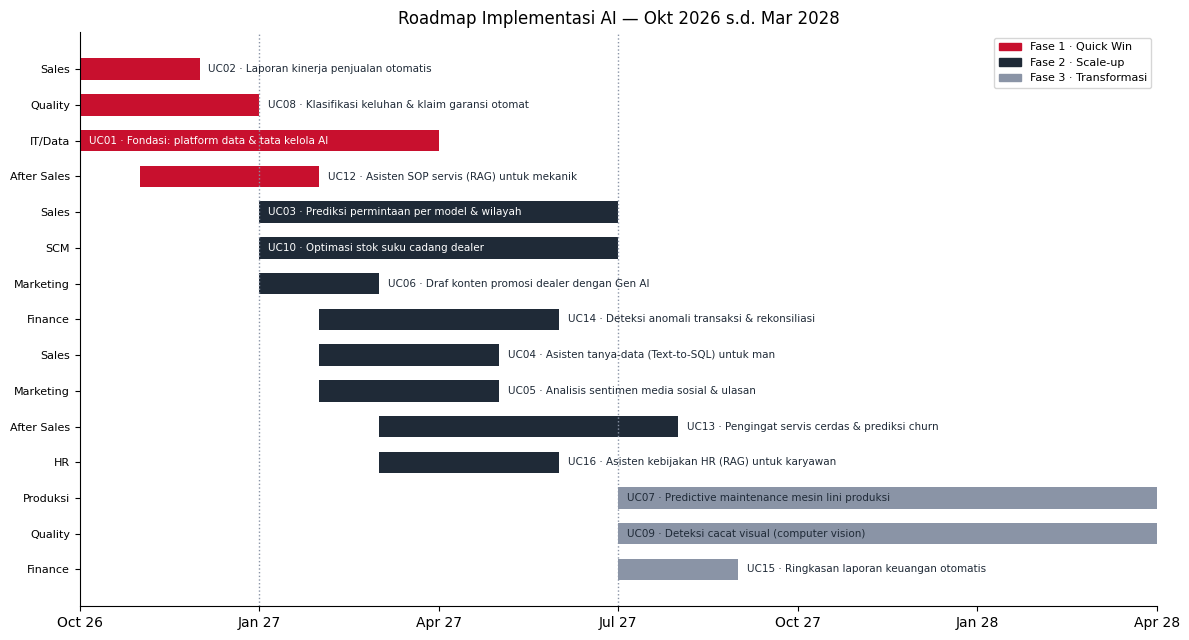

In [12]:
AWAL = pd.Timestamp("2026-10-01")
g = uc.dropna(subset=["mulai_bln"]).sort_values(["mulai_bln", "peringkat"], ascending=[False, False])

fig, ax = plt.subplots(figsize=(12, 6.5))
for i, (_, r) in enumerate(g.iterrows()):
    ax.barh(i, r["selesai_bln"] - r["mulai_bln"], left=r["mulai_bln"], color=WARNA_FASE[r["fase"]], height=0.6)
    label = f"{r['id']} · {r['use_case'][:42]}"
    if r["selesai_bln"] - r["mulai_bln"] >= 6:           # batang cukup panjang → label di dalam batang
        ax.text(r["mulai_bln"] + 0.15, i, label, va="center", fontsize=7.5,
                color="white" if r["fase"] != "Fase 3 · Transformasi" else GELAP)
    else:                                                # batang pendek → label di kanan batang
        ax.text(r["selesai_bln"] + 0.15, i, label, va="center", fontsize=7.5, color=GELAP)
for batas in (3, 9):
    ax.axvline(batas, color=ABU, linestyle=":", linewidth=1)
ax.set_yticks(range(len(g)))
ax.set_yticklabels(g["divisi"], fontsize=8)
bulan_label = [(AWAL + pd.DateOffset(months=m)).strftime("%b %y") for m in range(0, 19, 3)]
ax.set_xticks(range(0, 19, 3))
ax.set_xticklabels(bulan_label)
ax.set_xlim(0, 18)
ax.legend(handles=[Patch(color=c, label=f) for f, c in WARNA_FASE.items() if f != "Backlog"],
          loc="upper right", fontsize=8)
ax.set_title("Roadmap Implementasi AI — Okt 2026 s.d. Mar 2028")
plt.tight_layout()
plt.savefig("gantt_roadmap.png", dpi=150)
plt.show()

**Penjelasan kode**
- `dropna(subset=["mulai_bln"])` — membuang use case Backlog (tanpa jadwal).
- Urutan `ascending=False` — `barh` menggambar dari bawah ke atas, sehingga pembalikan urutan membuat proyek yang mulai paling awal tampil **di atas**.
- `ax.barh(y, lebar, left=mulai)` — batang horizontal dari bulan mulai sepanjang durasi: inti Gantt chart.
- Label ditaruh **di dalam** batang bila durasinya ≥ 6 bulan, dan **di kanan** batang bila pendek agar tidak terpotong. Warna teks putih di batang gelap, gelap di batang abu/latar putih → menjaga kontras.
- `axvline(3)` & `axvline(9)` — garis batas antar fase.
- `AWAL + pd.DateOffset(months=m)` → label sumbu-X berupa nama bulan nyata (Okt 26, Jan 27, …).
- `Patch(color, label)` — legenda manual karena warna ditentukan per batang.

## Langkah 7 — Arus kas & payback portofolio
Manfaat diasumsikan mulai **setelah** use case selesai, sebesar manfaat/12 per bulan. Biaya dibagi rata selama durasi pengerjaan.

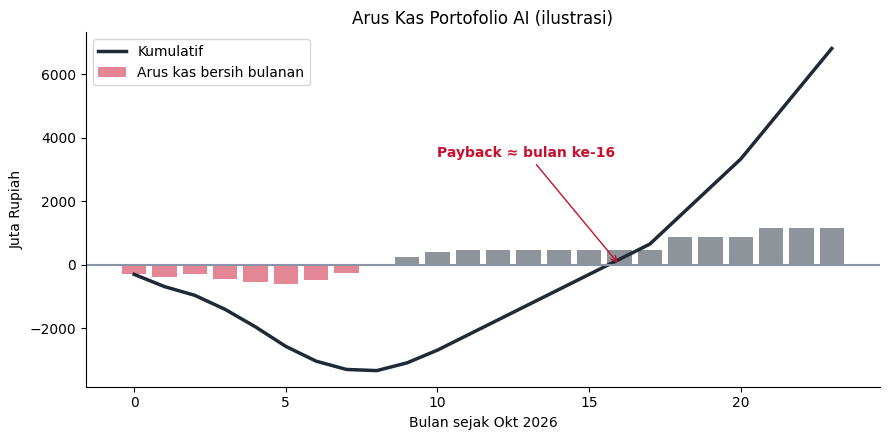

Portofolio aktif: biaya Rp7.500 juta | manfaat/tahun Rp13.920 juta | payback bulan ke-16


In [13]:
HORIZON = 24
arus = pd.DataFrame(0.0, index=range(HORIZON), columns=list(WARNA_FASE)[:3])
for _, r in uc.dropna(subset=["mulai_bln"]).iterrows():
    m0, m1 = int(r["mulai_bln"]), int(r["mulai_bln"] + r["durasi_bln"])
    for m in range(m0, min(m1, HORIZON)):
        arus.loc[m, r["fase"]] -= r["biaya_juta"] / r["durasi_bln"]          # pengeluaran
    for m in range(m1, HORIZON):
        arus.loc[m, r["fase"]] += r["manfaat_juta_thn"] / 12                 # manfaat setelah go-live

kumulatif = arus.sum(axis=1).cumsum()
payback = int(kumulatif[kumulatif >= 0].index.min()) if (kumulatif >= 0).any() else None

fig, ax = plt.subplots()
ax.bar(arus.index, arus.sum(axis=1), color=[MERAH if v < 0 else GELAP for v in arus.sum(axis=1)], alpha=0.5,
       label="Arus kas bersih bulanan")
ax.plot(kumulatif.index, kumulatif.values, color=GELAP, linewidth=2.5, label="Kumulatif")
ax.axhline(0, color=ABU)
if payback is not None:
    ax.annotate(f"Payback ≈ bulan ke-{payback}", (payback, 0), xytext=(payback - 6, kumulatif.max() * 0.5),
                arrowprops={"arrowstyle": "->", "color": MERAH}, color=MERAH, fontweight="bold")
ax.set_xlabel("Bulan sejak Okt 2026")
ax.set_ylabel("Juta Rupiah")
ax.set_title("Arus Kas Portofolio AI (ilustrasi)")
ax.legend()
plt.tight_layout()
plt.savefig("arus_kas.png", dpi=150)
plt.show()
aktif = uc[uc["fase"] != "Backlog"]
rp = lambda x: f"{x:,.0f}".replace(",", ".")
print(f"Portofolio aktif: biaya Rp{rp(aktif['biaya_juta'].sum())} juta | manfaat/tahun Rp{rp(aktif['manfaat_juta_thn'].sum())} juta"
      f" | payback bulan ke-{payback}")

**Penjelasan kode**
- `pd.DataFrame(0.0, index=range(24), columns=[fase...])` — tabel arus kas kosong: baris = bulan, kolom = fase.
- Loop pertama mengurangkan biaya per bulan selama pengerjaan (`biaya / durasi`); loop kedua menambahkan manfaat bulanan setelah go-live hingga akhir horizon.
- `arus.sum(axis=1).cumsum()` — arus kas bersih per bulan lalu dijumlah berjalan (kumulatif).
- `kumulatif[kumulatif >= 0].index.min()` — bulan pertama saat kumulatif menjadi positif = **payback portofolio**.
- `ax.annotate(..., arrowprops=...)` — anotasi ber-panah yang menunjuk titik payback.
- Grafik ini menjawab pertanyaan manajemen yang paling sering muncul: *"Kapan investasi AI ini kembali?"*

## Langkah 8 — Tata kelola: RACI per use case & KPI
**RACI** memperjelas peran: **R**esponsible (mengerjakan), **A**ccountable (penanggung jawab akhir), **C**onsulted (dimintai masukan), **I**nformed (diberi informasi).

In [14]:
def raci(r):
    return {
        "id": r["id"], "use_case": r["use_case"],
        "Responsible": f"AI Champion {r['divisi']} + Tim Data",
        "Accountable": f"Kepala Divisi {r['divisi']}",
        "Consulted": "IT Security & Data Governance" + (", Legal" if r["risiko"] >= 3 else ""),
        "Informed": "Komite AI / Manajemen",
        "KPI_utama": {"Sales": "akurasi forecast / waktu penyusunan laporan",
                      "Quality": "waktu klasifikasi klaim / % klaim tertangani",
                      "SCM": "hari persediaan & fill rate part",
                      "After Sales": "waktu penanganan servis & kepuasan pelanggan",
                      "Finance": "waktu tutup buku & anomali terdeteksi",
                      "Marketing": "engagement & waktu produksi konten",
                      "Produksi": "downtime mesin & OEE",
                      "HR": "waktu respons pertanyaan karyawan",
                      "IT/Data": "% data terkatalog & insiden keamanan"}[r["divisi"]],
    }


tabel_raci = pd.DataFrame([raci(r) for _, r in uc[uc["fase"] != "Backlog"].iterrows()])
tabel_raci.head(8)

,id,use_case,Responsible,Accountable,Consulted,Informed,KPI_utama
0,UC02,Laporan kinerja penjualan otomatis,AI Champion Sales + Tim Data,Kepala Divisi Sales,IT Security & Data Governance,Komite AI / Manajemen,akurasi forecast / waktu penyusunan laporan
1,UC03,Prediksi permintaan per model & wilayah,AI Champion Sales + Tim Data,Kepala Divisi Sales,IT Security & Data Governance,Komite AI / Manajemen,akurasi forecast / waktu penyusunan laporan
2,UC08,Klasifikasi keluhan & klaim garansi otomatis,AI Champion Quality + Tim Data,Kepala Divisi Quality,IT Security & Data Governance,Komite AI / Manajemen,waktu klasifikasi klaim / % klaim tertangani
3,UC12,Asisten SOP servis (RAG) untuk mekanik,AI Champion After Sales + Tim Data,Kepala Divisi After Sales,IT Security & Data Governance,Komite AI / Manajemen,waktu penanganan servis & kepuasan pelanggan
4,UC10,Optimasi stok suku cadang dealer,AI Champion SCM + Tim Data,Kepala Divisi SCM,IT Security & Data Governance,Komite AI / Manajemen,hari persediaan & fill rate part
5,UC06,Draf konten promosi dealer dengan Gen AI,AI Champion Marketing + Tim Data,Kepala Divisi Marketing,"IT Security & Data Governance, Legal",Komite AI / Manajemen,engagement & waktu produksi konten
6,UC07,Predictive maintenance mesin lini produksi,AI Champion Produksi + Tim Data,Kepala Divisi Produksi,IT Security & Data Governance,Komite AI / Manajemen,downtime mesin & OEE
7,UC14,Deteksi anomali transaksi & rekonsiliasi,AI Champion Finance + Tim Data,Kepala Divisi Finance,"IT Security & Data Governance, Legal",Komite AI / Manajemen,waktu tutup buku & anomali terdeteksi


**Penjelasan kode**
- `raci(r)` — membangkitkan peran standar dari atribut use case. Use case berisiko ≥ 3 otomatis melibatkan **Legal** sebagai *Consulted* — contoh aturan tata kelola yang dikodekan.
- KPI utama dipetakan per divisi melalui dict; setiap use case wajib punya KPI terukur sebelum dimulai (*no KPI, no project*).

## Langkah 9 — Narasi roadmap (LLM, berbasis fakta) & ekspor Excel

In [15]:
ringkas = (uc[uc["fase"] != "Backlog"].groupby("fase")
             .agg(jumlah=("id", "count"), biaya_juta=("biaya_juta", "sum"), contoh=("use_case", list)))
fakta = {
    "horizon": "Okt 2026 – Mar 2028",
    "jumlah_use_case": int((uc["fase"] != "Backlog").sum()),
    "total_biaya_juta": int(uc.loc[uc["fase"] != "Backlog", "biaya_juta"].sum()),
    "total_manfaat_juta_thn": int(uc.loc[uc["fase"] != "Backlog", "manfaat_juta_thn"].sum()),
    "payback_bulan_portofolio": payback,
    "ringkasan_fase": {f: {"jumlah": int(r.jumlah), "biaya_juta": int(r.biaya_juta), "contoh": r.contoh}
                       for f, r in ringkas.iterrows()},
    "dimensi_terlemah_umum": asesmen["Dimensi terlemah"].mode()[0],
}
narasi = llm.generate(f"""TUGAS: NARASI_ROADMAP
PERAN: Kepala Transformasi Digital. Tulis ringkasan roadmap AI (maks. 180 kata) untuk Direksi.
BATASAN: gunakan hanya angka pada FAKTA; sebut tiap fase dan satu prioritas fondasi.
FAKTA: {json.dumps(fakta, ensure_ascii=False)} AKHIR_FAKTA""")
print(narasi)

with pd.ExcelWriter("Roadmap_AI_per_Divisi.xlsx", engine="openpyxl") as xw:
    asesmen.to_excel(xw, sheet_name="Asesmen_Kematangan")
    uc.to_excel(xw, sheet_name="Prioritas_UseCase", index=False)
    tabel_raci.to_excel(xw, sheet_name="RACI_KPI", index=False)
    arus.assign(kumulatif=kumulatif).to_excel(xw, sheet_name="Arus_Kas", index_label="bulan_ke")
    pd.DataFrame({"narasi": narasi.splitlines()}).to_excel(xw, sheet_name="Ringkasan", index=False)
print("\nFile tersimpan: Roadmap_AI_per_Divisi.xlsx")

Roadmap AI Okt 2026 – Mar 2028 memuat 15 use case dengan total investasi Rp7.500 juta dan estimasi manfaat Rp13.920 juta per tahun (payback portofolio ±16 bulan).

• Fase 1 · Quick Win: 4 use case, biaya Rp1.530 juta — contoh: Laporan kinerja penjualan otomatis; Klasifikasi keluhan & klaim garansi otomatis.
• Fase 2 · Scale-up: 8 use case, biaya Rp2.950 juta — contoh: Prediksi permintaan per model & wilayah; Optimasi stok suku cadang dealer.
• Fase 3 · Transformasi: 3 use case, biaya Rp3.020 juta — contoh: Predictive maintenance mesin lini produksi; Deteksi cacat visual (computer vision).

Prioritas penguatan fondasi: dimensi SDM menjadi titik terlemah di sebagian besar divisi. Keberhasilan Fase 1 menjadi syarat pendanaan Fase 2.

File tersimpan: Roadmap_AI_per_Divisi.xlsx


**Penjelasan kode**
- `groupby("fase").agg(jumlah=("id","count"), ...)` — *named aggregation*: menentukan nama kolom hasil sekaligus kolom sumber & fungsi agregasinya. `("use_case", list)` mengumpulkan nama use case menjadi list.
- `asesmen["Dimensi terlemah"].mode()[0]` — modus: dimensi yang paling sering menjadi titik terlemah di seluruh divisi.
- Prompt narasi mengikuti pola Materi 4: **fakta dihitung Python → LLM menulis → hanya angka dari fakta**.
- `pd.ExcelWriter` menulis 5 sheet: asesmen, prioritas, RACI & KPI, arus kas, dan ringkasan — satu file yang bisa langsung dipakai pada rapat roadmap.
- `index_label="bulan_ke"` — memberi nama kolom indeks pada sheet arus kas.

## Ringkasan alur roadmap
| Langkah | Keluaran | Pertanyaan yang dijawab |
|---|---|---|
| Asesmen kematangan | Radar 6 dimensi | Seberapa siap setiap divisi? |
| Inventaris + ide LLM | Daftar use case tervalidasi | Apa yang bisa dikerjakan? |
| Skor berbobot + sensitivitas | Peringkat stabil | Mana yang paling penting? |
| Matriks prioritas | 4 kuadran | Mana yang cepat & bernilai? |
| Fase & Gantt | Jadwal 18 bulan | Kapan dikerjakan? |
| Arus kas | Payback | Kapan investasi kembali? |
| RACI & KPI | Peran & ukuran sukses | Siapa bertanggung jawab & bagaimana diukur? |

## Latihan
1. Isi ulang `asesmen` dan `use_case` dengan hasil diskusi divisi Anda, lalu jalankan ulang seluruh notebook.
2. Tambahkan kriteria **"keselarasan strategi"** ke `BOBOT` (sesuaikan bobot lain agar total tetap 1). Bagaimana perubahan 5 besar?
3. Ubah batas proyek serentak dari 3 menjadi 2 (`// 2`). Bagaimana dampaknya pada payback?
4. Tambahkan usulan LLM yang berstatus "diterima" ke `use_case`, beri estimasi biaya & manfaat, lalu hitung ulang prioritasnya.